# Tarea 2: plan de entrega de clientes
Analiza el plan de entrega (90 clientes; plan vs compra real) para responder: ¿hay sesgo en el plan?, ¿cuántas compras son fuera de plan y dónde se concentran?, ¿qué métricas adicionales conviene seguir? y ¿cómo aplanar la curva del martes? Toda la lógica vive en `src/logforecast` (`plan_analysis`, `plots`).

**Orden:**
1. Desvío del real contra el plan, por cliente y por CD y canal (gráficos).
2. Tablas: bias del plan, tasa de compras fuera de plan y concentración de desvíos.
3. Conclusiones y estrategia.

**Definiciones:** desvío de volumen = `(real − plan) / plan`; desvío de fecha = `fecha_compra_real − fecha_plan` en días; una compra es *fuera de plan* cuando así la marca el dato (`fuera_de_plan = 1`).

In [1]:
import pandas as pd

from logforecast import io, plan_analysis, plots
from logforecast.config import Settings

S = Settings.from_env()
plan, orders = io.load_plan(S), io.load_orders(S)

## 1. Desvío del real contra el plan
**Por cliente** (un panel por CD): barras = desvío medio de volumen ± desviación; puntos rojos = compras fuera de plan.

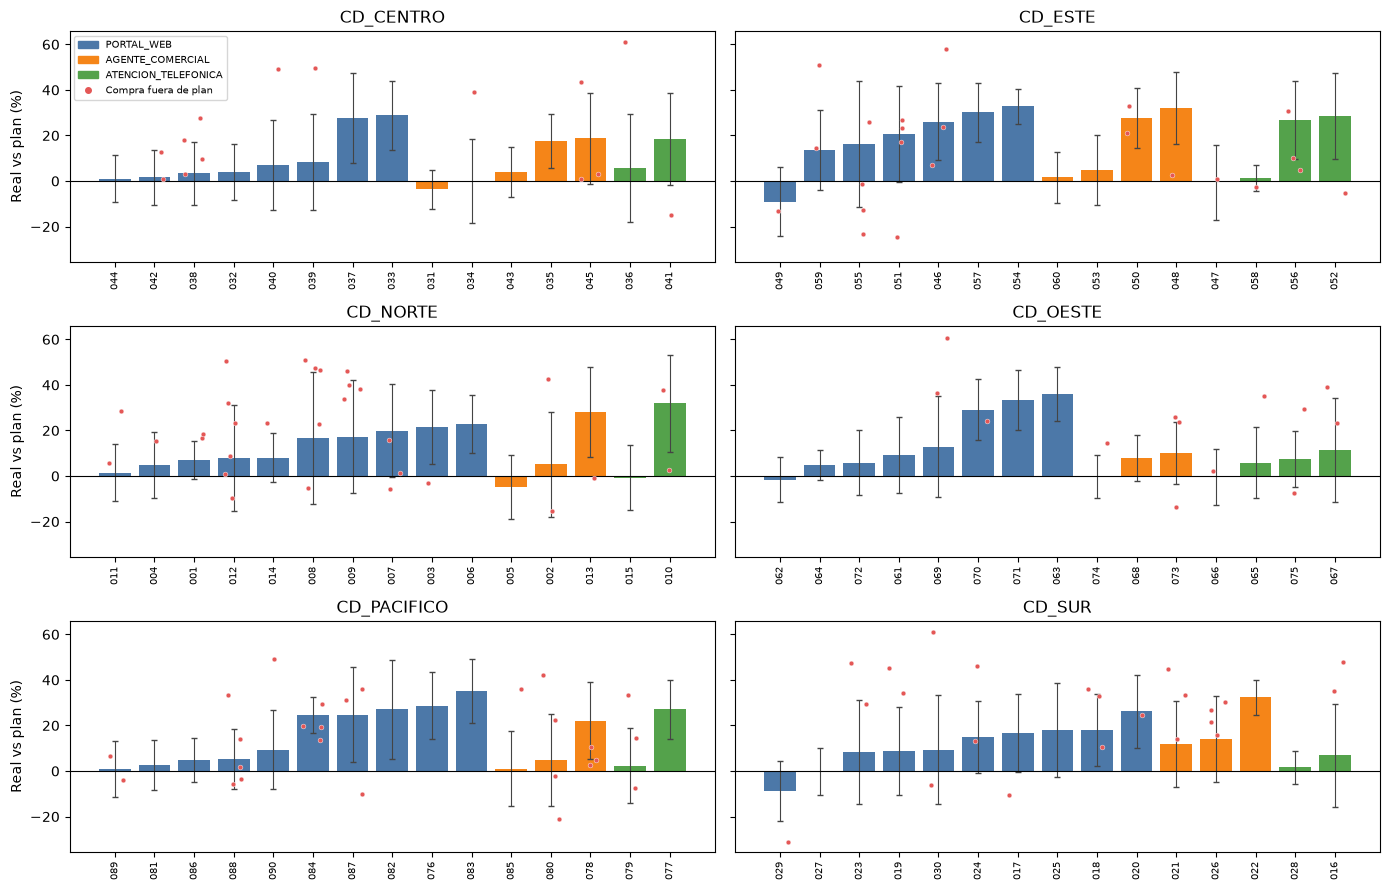

In [2]:
plots.plot_plan_deviation_by_client(plan)

**Por CD y canal:** desvío de volumen (izquierda) y de fecha en días (derecha). Los puntos rojos son compras fuera de plan; si salen del rango del gráfico se muestran en el borde.

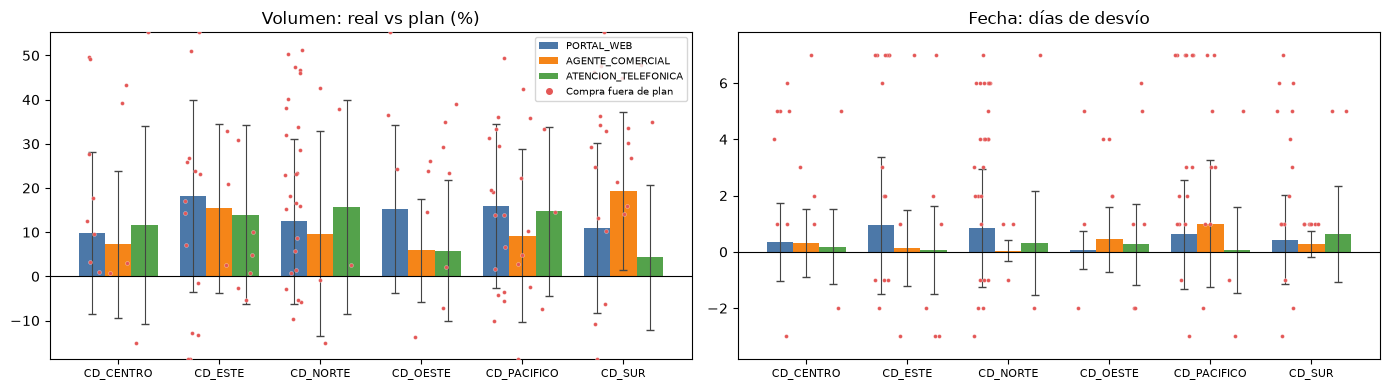

In [3]:
plots.plot_plan_deviation_by_cd_channel(plan)

## 2. Tablas: bias del plan, compras fuera de plan y concentración

In [4]:
print(plan_analysis.plan_bias(plan))
display(plan_analysis.out_of_plan_rate(plan))
display(plan_analysis.out_of_plan_rate(plan, 'centro_distribucion'))
display(plan_analysis.out_of_plan_rate(plan_analysis.enrich_plan(plan), 'dow_plan'))
plan_analysis.deviation_concentration(plan)

{'bias_unidades': 0.10617604720714775, 'wape_unidades': 0.15629005901653636, 'desvio_fecha_medio_dias': 0.4438430311231394, 'desvio_fecha_mediano_dias': 0.0}


,fuera_de_plan,n
0,0.17456,739


,centro_distribucion,fuera_de_plan,n
2,CD_NORTE,0.243902,123
4,CD_PACIFICO,0.213115,122
1,CD_ESTE,0.194915,118
5,CD_SUR,0.188525,122
0,CD_CENTRO,0.111111,126
3,CD_OESTE,0.101562,128


,dow_plan,fuera_de_plan,n
3,Mie,0.229358,109
1,Lun,0.221154,104
2,Mar,0.162162,259
4,Vie,0.155172,116
0,Jue,0.139073,151


0.4745558542287476

**¿Las diferencias en la tasa fuera de plan son significativas?** Test chi² de independencia (H0: la tasa es igual en todos los grupos) por CD y por día de la semana planificado.

In [5]:
pd.DataFrame({by: plan_analysis.out_of_plan_chi2(plan, by) for by in ['centro_distribucion', 'dow_plan']}).T

,chi2,gl,p_valor,n
centro_distribucion,14.121648,5.0,0.014855,739.0
dow_plan,5.737148,4.0,0.219657,739.0


**Cobertura del plan:** clientes, % del volumen total de pedidos y % de fechas planificadas en fin de semana.

In [6]:
pd.Series(plan_analysis.plan_coverage(plan, orders))

clientes                  90.000000
cobertura_volumen          0.150202
pct_plan_fin_de_semana     0.000000
dtype: float64

**Bias del plan en detalle:** % de compras y de clientes con real > plan, y bias por CD, por canal y según si la compra fue en plan (0) o fuera de plan (1).

In [7]:
display(pd.Series(plan_analysis.plan_bias_detail(plan)))
display(plan_analysis.plan_bias_by(plan, 'centro_distribucion'))
display(plan_analysis.plan_bias_by(plan, 'canal_venta'))
plan_analysis.plan_bias_by(plan, 'fuera_de_plan')

pct_compras_real_sobre_plan     0.711773
clientes_real_sobre_plan       81.000000
clientes                       90.000000
dtype: float64

,centro_distribucion,bias_unidades,n
1,CD_ESTE,0.141024,118
4,CD_PACIFICO,0.128359,122
2,CD_NORTE,0.110070,123
5,CD_SUR,0.103145,122
3,CD_OESTE,0.092045,128
0,CD_CENTRO,0.082190,126


,canal_venta,bias_unidades,n
1,ATENCION_TELEFONICA,0.108334,131
2,PORTAL_WEB,0.107834,435
0,AGENTE_COMERCIAL,0.099260,173


,fuera_de_plan,bias_unidades,n
1,1,0.168700,129
0,0,0.089434,610


**Desvío de fecha en compras fuera de plan:** dirección (antes/después), magnitud en días y día de la semana en que aterriza la compra real.

In [8]:
pd.Series(plan_analysis.out_of_plan_date_shift(plan))

n_fuera_de_plan               129.000000
pct_despues                     0.775194
pct_antes                       0.224806
desvio_medio_neto_dias          2.542636
atraso_medio_dias               3.840000
atraso_max_dias                 7.000000
adelanto_min_dias              -1.000000
adelanto_max_dias              -3.000000
pct_aterriza_martes             0.596899
pct_aterriza_fin_de_semana      0.170543
dtype: float64

**Adhesión por cliente y concentración de compras fuera de plan** (top 20% de clientes ordenados por número de compras fuera de plan).

In [9]:
display(pd.Series(plan_analysis.adherence_summary(plan)))
plan_analysis.out_of_plan_concentration(plan)

clientes_nunca_fuera    31.000000
clientes_fuera_>=30%    20.000000
max_pct_fuera_plan       0.666667
dtype: float64

0.5271317829457365

**Peso de cada día de la semana:** % de unidades planificadas (`fecha_plan`), reales del plan (`fecha_compra_real`) y de los pedidos totales (`fecha_despacho`), contra una distribución uniforme.

In [10]:
plan_analysis.weekday_share(plan, orders)

,pct_unidades_plan,pct_unidades_reales_plan,pct_pedidos_totales,uniforme
dia,,,,
Lun,0.133334,0.096513,0.130377,0.142857
Mar,0.330099,0.462024,0.166294,0.142857
Mie,0.194619,0.137904,0.132845,0.142857
Jue,0.154348,0.127862,0.147670,0.142857
Vie,0.187601,0.140579,0.150942,0.142857
Sab,0.000000,0.009099,0.147295,0.142857
Dom,0.000000,0.026019,0.124576,0.142857


## 3. Conclusiones
*Nota: el plan cubre 90 clientes (~15% del volumen total) y solo tiene días hábiles. Las conclusiones valen para esa muestra.*

### 1. ¿Existe bias en el plan?

**Sí, en unidades: el plan subestima sistemáticamente lo que los clientes compran.**
- Bias de **+10,6%** (WAPE 15,6%). En el 71% de las compras el real supera al plan, y 81 de los 90 clientes compran más de lo planificado.
- Es consistente entre CDs (+8,2% CENTRO a +14,1% ESTE) y entre canales (+9,9% a +10,8%), por lo que parece un sesgo del proceso de planificación y no de un CD o canal puntual.
- Las compras que cumplen la fecha también superan el plan (+8,9%), y las que están fuera de plan lo superan más (+16,9%).

**En fechas, el sesgo es menor y se concentra en los desvíos.**
- La mediana de desvío es 0 días (la mayoría compra en la fecha) y la media +0,44 días.
- Entre las compras fuera de plan, el 77,5% ocurre **después** de lo planificado (atraso medio +3,8 días, hasta +7) y el 22,5% antes (−1 a −3 días). Considerando ambos sentidos, el desvío medio neto es +2,5 días.

### 2. Compras fuera de plan

- **Total: 17,5%** (129 de 739 compras).
- **Por CD** (diferencia significativa, chi² p = 0,015): NORTE 24,4%, PACIFICO 21,3%, ESTE 19,5%, SUR 18,9%, CENTRO 11,1%, OESTE 10,2%.
- **Por día de la semana planificado:** miércoles 22,9%, lunes 22,1%, martes 16,2%, viernes 15,5%, jueves 13,9%. Esta diferencia **no es estadísticamente significativa** (chi² p = 0,22), por lo que no conviene atribuirla a un día concreto.
- **Adónde van las compras fuera de plan:** el 59,7% termina cayendo en martes y el 17% cae en fin de semana, que el plan no contempla.

### 3. Métricas adicionales

| Métrica | Por qué aporta |
|---|---|
| **Adhesión por cliente** (% de compras en la fecha planificada) | Separa a los clientes confiables de los que no. 31 de 90 nunca se salen del plan y 20 se salen en ≥30% de sus compras (máximo 67%). |
| **Variación de fecha con signo** (días real − plan) | Distingue adelantar de atrasar, que tienen costos logísticos distintos. |
| **Variación de volumen por compra** (% real vs plan) | Mide cuánto se desvía cada compra, no solo el total. |
| **Concentración de desvíos** | Ordenando por desvío absoluto en unidades, el 20% de los clientes explica el 47,5% del desvío. Ordenando por número de compras fuera de plan, el 20% de los clientes concentra el 52,7% de esas compras. Son grupos distintos de clientes, pero en ambos casos basta intervenir en pocos. |
| **Día de aterrizaje de las compras fuera de plan** | Muestra hacia qué días se desplaza la demanda (el martes concentra el 60%). |
| **Utilización de capacidad por CD y día** | Conecta los desvíos con el riesgo operativo (días sobre el 90% de capacidad). |

### 4. Estrategia para aplanar la curva del martes

**Diagnóstico.** El martes concentra el 33% de las unidades planificadas, y las compras reales de la muestra se concentran aún más (46% de las unidades). Además, los clientes que se salen del plan tienden a ir hacia el martes. En el total de pedidos el pico es más suave (16,6% vs ~14,3% si fuera uniforme), por lo que el 46% no debe extrapolarse al negocio completo.

**Mecanismo: recomendación de fecha con capacidad y con incentivo.** La plataforma ya recomienda fechas de despacho dinámicas. Se propone:
1. **Segmentar a los clientes por flexibilidad**, usando adhesión y variación de fecha. Los flexibles son el objetivo principal.
2. **Estimar la utilización esperada por CD y día** como pronóstico corregido ÷ capacidad. El endpoint de inferencia ya entrega esa cifra (`capacidad_maxima`, `uso_capacidad` y `alerta_capacidad`; ver notebooks 06 y 07).
3. **Cuando un día supere un umbral** (por ejemplo 85–90%), ofrecer fechas alternativas cercanas con un incentivo (descuento, flete sin costo o prioridad de despacho) y mostrar la capacidad restante.
4. **Poner cupos blandos al martes** para los clientes flexibles, sin forzar a los clientes de baja flexibilidad.

**Implementación.** Piloto en un CD, por ejemplo NORTE, que combina la mayor tasa fuera de plan (24,4%) y más días sobre la capacidad (6 de los 13 CD-día en que el real superó el tope; ver notebook 07). Se compara contra un CD de control durante 4 a 8 semanas.

**KPIs**
- **Principal:** razón pico/promedio diaria por CD (máximo ÷ media de unidades por día).
- Coeficiente de variación de la demanda diaria.
- % de días sobre el 90% de capacidad y número de fletes de emergencia.
- % de la demanda que cae en martes.
- Tasa de aceptación de la fecha alternativa y adhesión al plan, para controlar que el incentivo funcione sin deteriorar el servicio.